In [67]:
import pandas as pd
import matplotlib.pyplot as plt
import os

In [68]:
anos = [ano for ano in range (2016, 2026)]

In [69]:
os.listdir(path+'/goal_programming/')

['carteiras_goal_programming.csv']

In [70]:
os.listdir(path)

['goal_programming',
 'minima_variancia',
 'retorno_magic_formula_sharpe_bissecao',
 'retorno_piotroski_sharpe_bissecao',
 'sharpe_linear_magic_formula',
 'sharpe_linear_piotroski']

In [82]:
acumulado

date
2025-04-01    101.281180
2025-04-02    101.908523
2025-04-03    101.740015
2025-04-04     99.256412
2025-04-07     97.788641
                 ...    
2026-03-25    151.399599
2026-03-26    148.333734
2026-03-27    146.139888
2026-03-30    147.527025
2026-03-31    153.374004
Length: 250, dtype: float64

In [91]:
path = '../carteiras/'

lista_df = []
dicio_anos = {}
for ano in anos:
    for file in os.listdir(path):
        arquivo = os.listdir(os.path.join(path, file))
        caminho = os.path.join(path, file, arquivo[0])
        df = pd.read_csv(caminho)
        df_ano = df[df["ano"] == ano]
        # print(f'Carteira: {file}: {len(df_ano)}')
        ativos = df_ano["ativo"].unique().tolist()
        # print(f"Ativos da Carteira: {ano}",ativos)
        # retornos
        retorno_path = f'../dados_retornos/plotagem/dados/ativo/df_acumulados_ativos_{ano}.csv'
        retornos = pd.read_csv(retorno_path).set_index('date')
        # print(f"Ativos dos retornos: {ano}",retornos[ativos].columns.tolist())
        retornos = retornos[ativos]

        pesos = df_ano.set_index('ativo')['peso']

        carteira_retorno = (retornos * pesos).sum(axis=1)
        carteira_otimizada = carteira_retorno + 1
        acumulado = carteira_otimizada.cumprod()*100
        print(f"file: {file}, ano: {ano}, acumulado: {acumulado.values[-1]}")
        lista_df.append(acumulado)
        dicio_anos[ano] = {f'{file}_{ano}': lista_df}
        



file: goal_programming, ano: 2016, acumulado: 137.29681767131473
file: minima_variancia, ano: 2016, acumulado: 163.85911257913972
file: retorno_magic_formula_sharpe_bissecao, ano: 2016, acumulado: 145.63942205258658
file: retorno_piotroski_sharpe_bissecao, ano: 2016, acumulado: 146.63604792230632
file: sharpe_linear_magic_formula, ano: 2016, acumulado: 145.6665000027804
file: sharpe_linear_piotroski, ano: 2016, acumulado: 131.2719350641416
file: goal_programming, ano: 2017, acumulado: 145.46652279091424
file: minima_variancia, ano: 2017, acumulado: 147.07942409537378
file: retorno_magic_formula_sharpe_bissecao, ano: 2017, acumulado: 152.97608562917597
file: retorno_piotroski_sharpe_bissecao, ano: 2017, acumulado: 149.04953548985426
file: sharpe_linear_magic_formula, ano: 2017, acumulado: 169.65272052820157
file: sharpe_linear_piotroski, ano: 2017, acumulado: 150.39798707713373
file: goal_programming, ano: 2018, acumulado: 106.90684447126199
file: minima_variancia, ano: 2018, acumulado:

## --------------------

In [111]:
for i,j in carteiras.items():
    print(i,"->",j)

goal_programming ->      Unnamed: 0   ano  ativo  peso
0             0  2016  ABEV3  0.02
1             1  2016  COGN3  0.02
2             2  2016  FLRY3  0.20
3             3  2016  ISAE4  0.02
4             4  2016  LREN3  0.20
..          ...   ...    ...   ...
104         104  2026  JHSF3  0.20
105         105  2026  LREN3  0.20
106         106  2026  PETR3  0.02
107         107  2026  PETR4  0.02
108         108  2026  TEND3  0.02

[109 rows x 4 columns]
minima_variancia ->      Unnamed: 0   ano   ativo    peso
0             0  2016   BRKM5  0.0528
1             1  2016   EMBJ3  0.0685
2             2  2016  ENGI11  0.1592
3             3  2016   HYPE3  0.2000
4             4  2016   JHSF3  0.0468
..          ...   ...     ...     ...
105         105  2026   POMO4  0.0657
106         106  2026   PRIO3  0.1186
107         107  2026   PSSA3  0.0776
108         108  2026   SUZB3  0.2000
109         109  2026   TOTS3  0.0594

[110 rows x 4 columns]
retorno_magic_formula_sharpe_bisseca

In [113]:
dicio_anos[2016]

{'goal_programming': date
 2016-04-01    100.016819
 2016-04-04     98.688387
 2016-04-05     99.139776
 2016-04-06     98.263207
 2016-04-07    100.314886
                  ...    
 2017-03-27    134.262591
 2017-03-28    136.421772
 2017-03-29    137.828046
 2017-03-30    137.690759
 2017-03-31    137.296818
 Length: 251, dtype: float64,
 'minima_variancia': date
 2016-04-01    101.378716
 2016-04-04     98.517289
 2016-04-05     97.198430
 2016-04-06     95.646716
 2016-04-07     95.839388
                  ...    
 2017-03-27    159.980964
 2017-03-28    159.988797
 2017-03-29    161.298321
 2017-03-30    162.568213
 2017-03-31    163.859113
 Length: 251, dtype: float64,
 'retorno_magic_formula_sharpe_bissecao': date
 2016-04-01    100.764138
 2016-04-04     98.160949
 2016-04-05     98.156117
 2016-04-06     97.057386
 2016-04-07     97.419357
                  ...    
 2017-03-27    145.571487
 2017-03-28    145.489226
 2017-03-29    146.942988
 2017-03-30    146.518993
 2017-03-

In [102]:
path = '../carteiras/'
modelos = sorted(os.listdir(path))

# lê cada carteira uma vez só
carteiras = {}
for modelo in modelos:
    arquivo = os.listdir(os.path.join(path, modelo))[0]
    carteiras[modelo] = pd.read_csv(os.path.join(path, modelo, arquivo))

# dicio_anos[ano][modelo] = série acumulada daquela carteira naquele ano
dicio_anos = {}
for ano in anos:
    retornos = pd.read_csv(f'../dados_retornos/plotagem/dados/ativo/df_acumulados_ativos_{ano}.csv',
                           index_col='date', parse_dates=True)
    dicio_anos[ano] = {}                      # <- zera a cada ano
    for modelo, df in carteiras.items():
        pesos = df[df['ano'] == ano].set_index('ativo')['peso']
        carteira_retorno = (retornos[pesos.index] * pesos).sum(axis=1)
        dicio_anos[ano][modelo] = (1 + carteira_retorno).cumprod() * 100

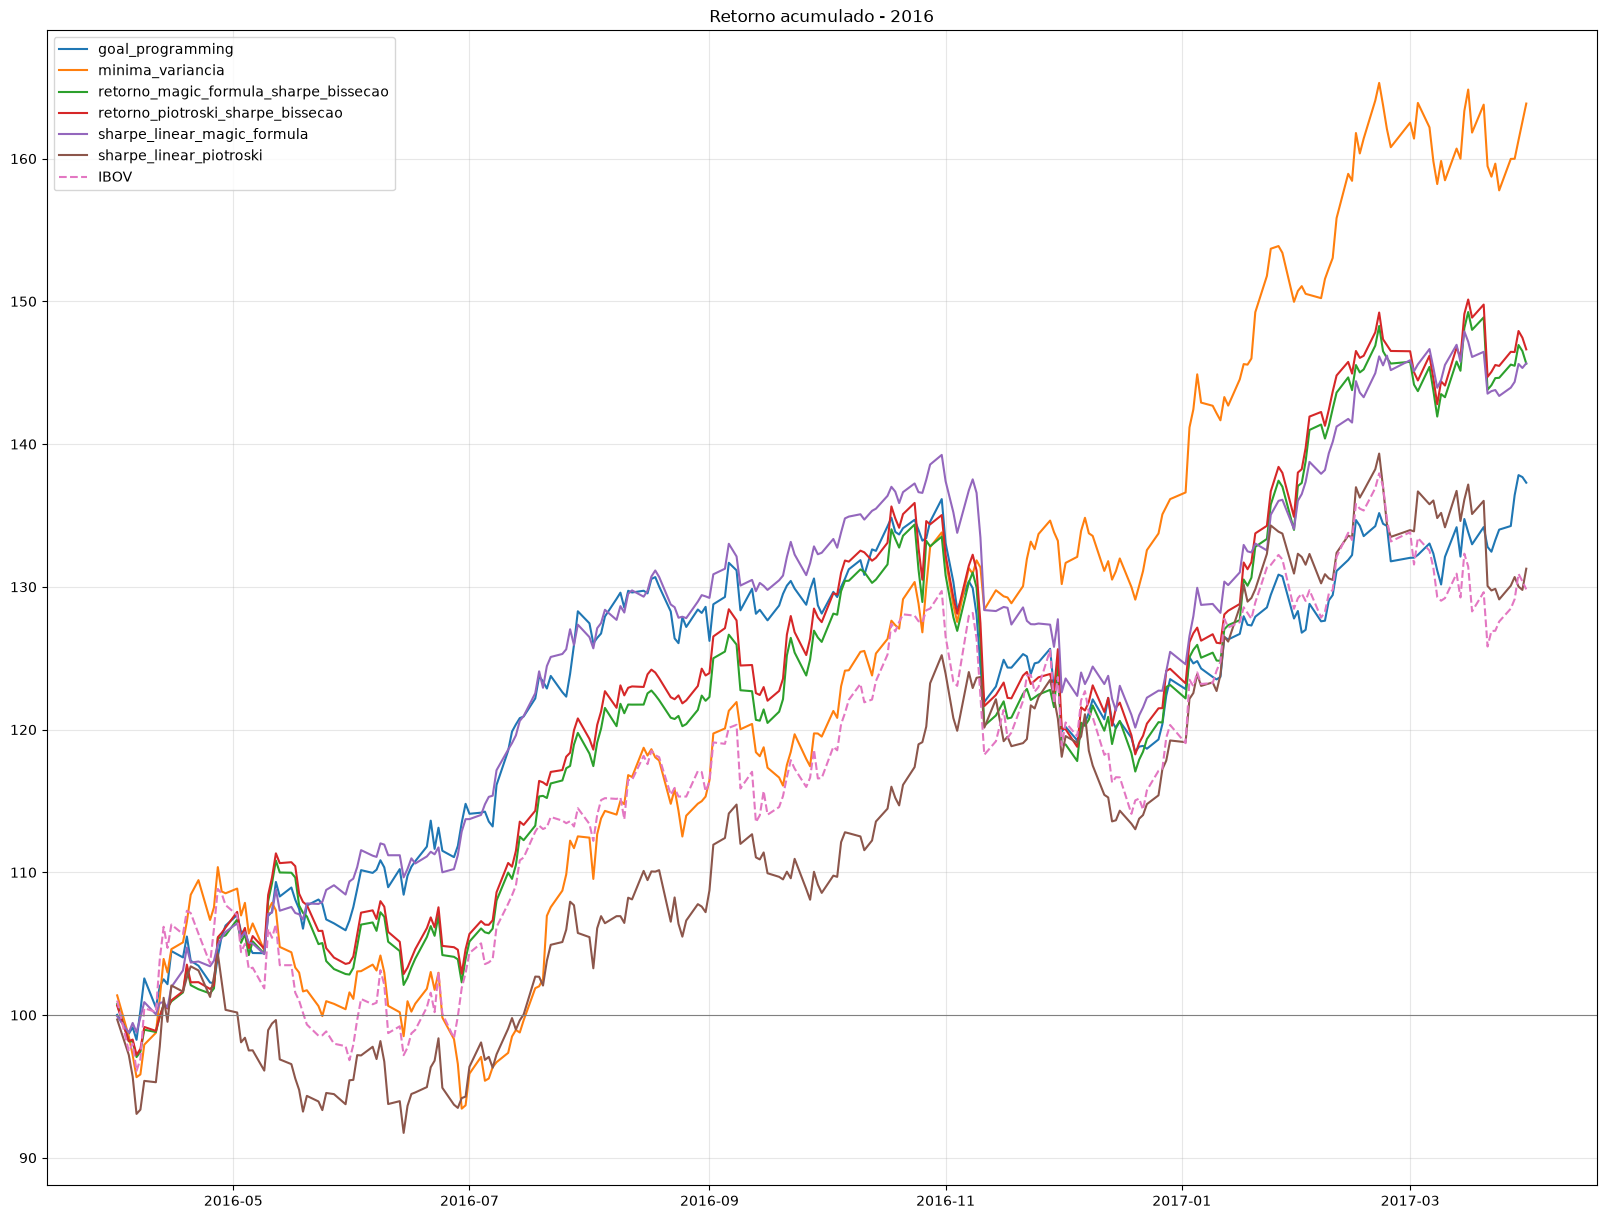

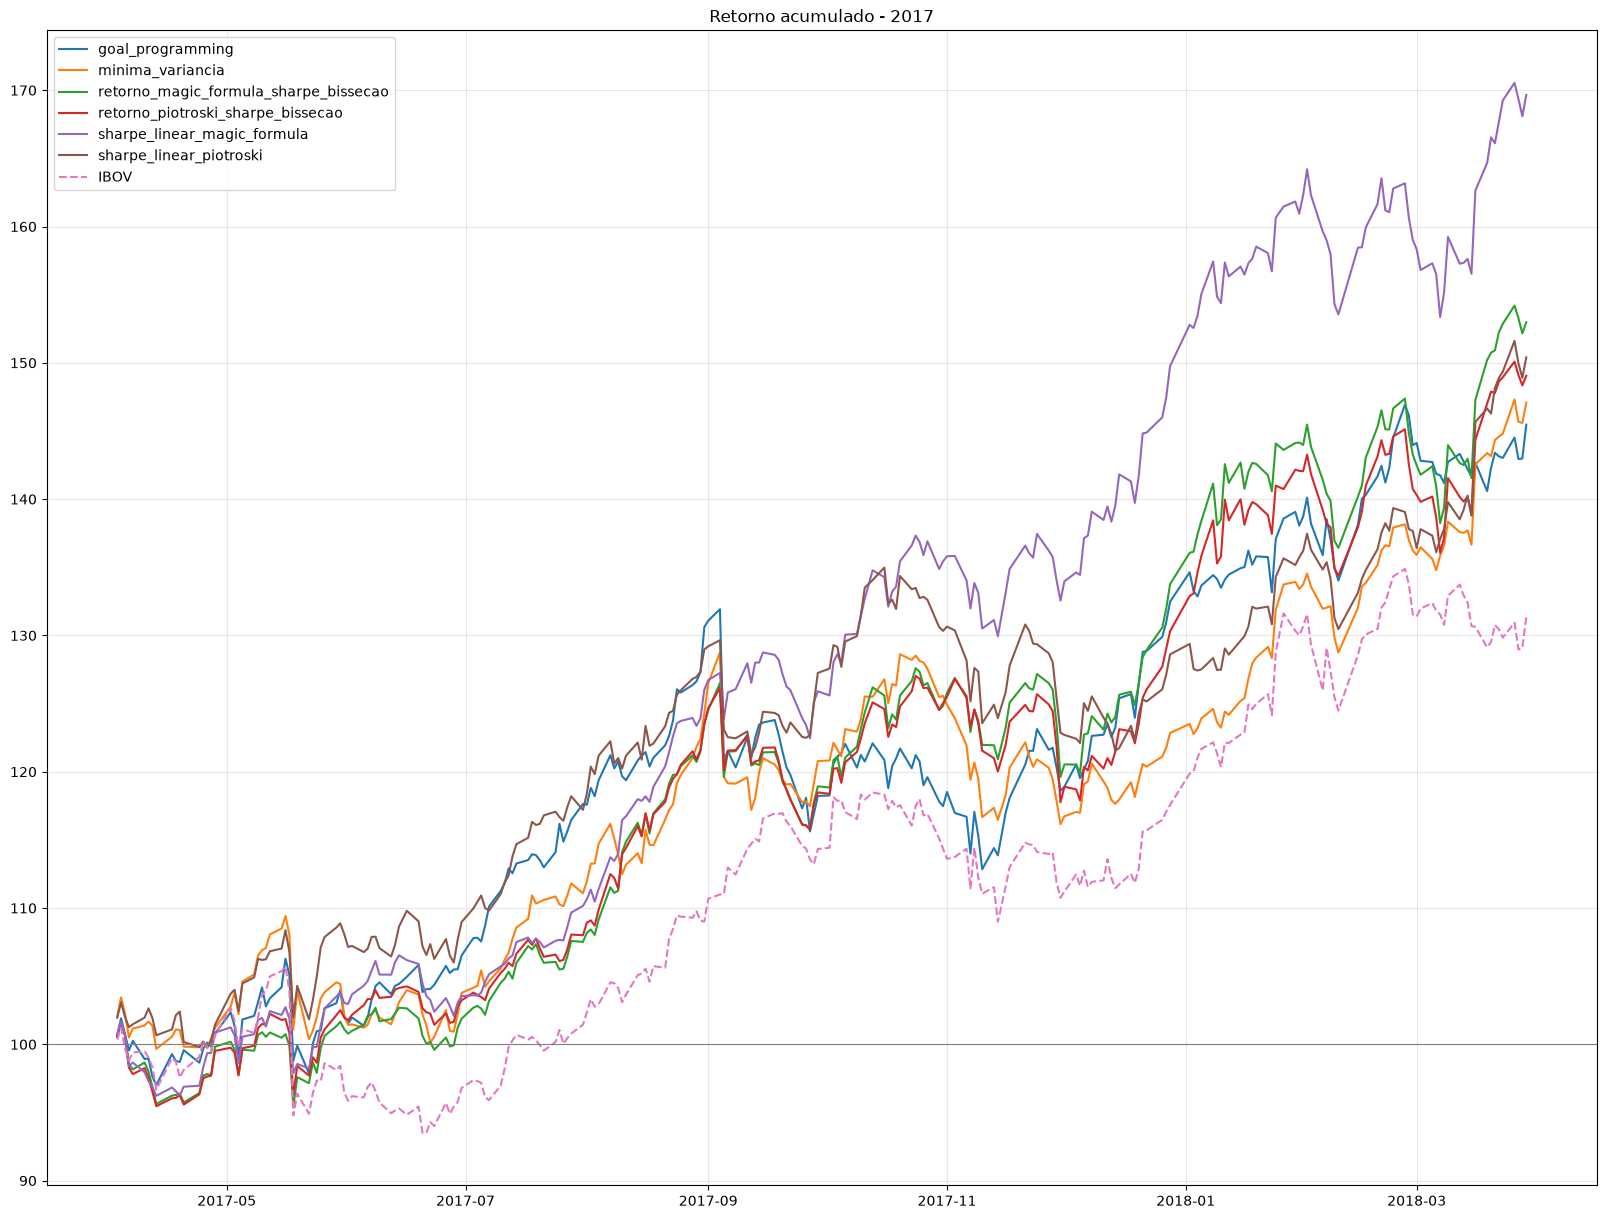

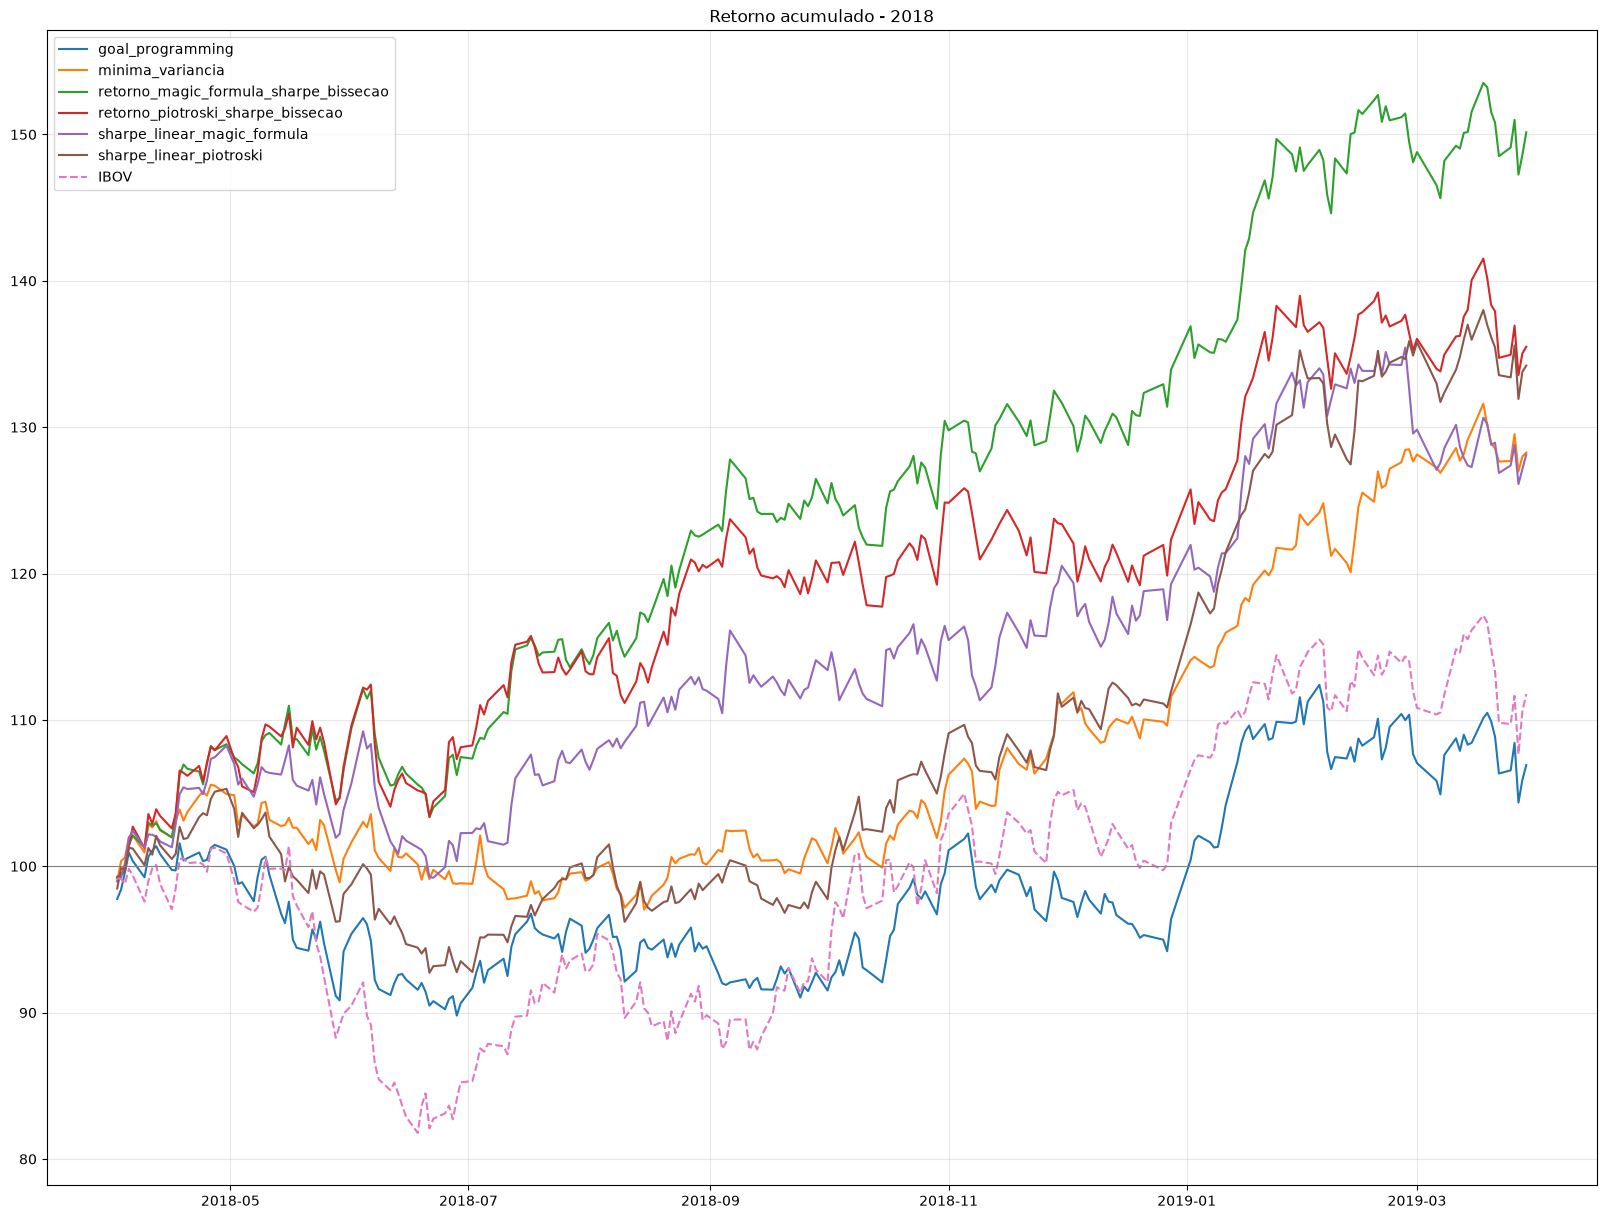

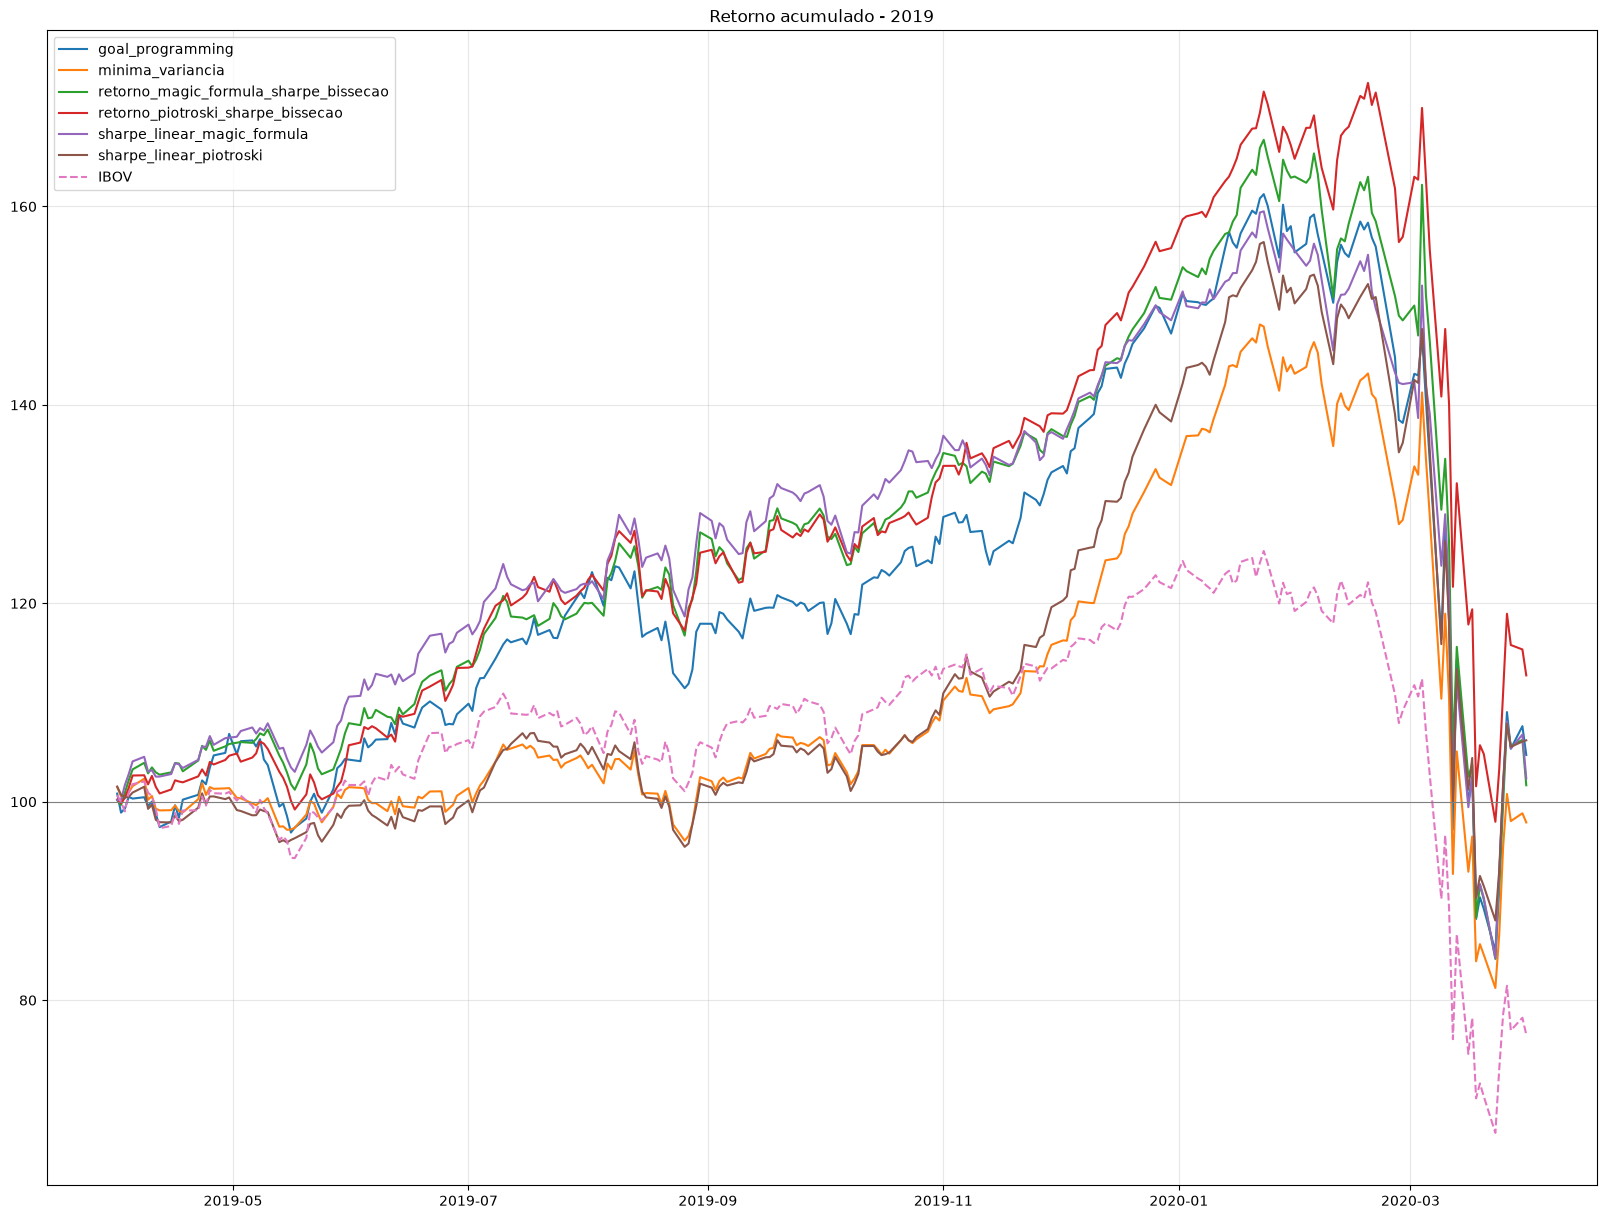

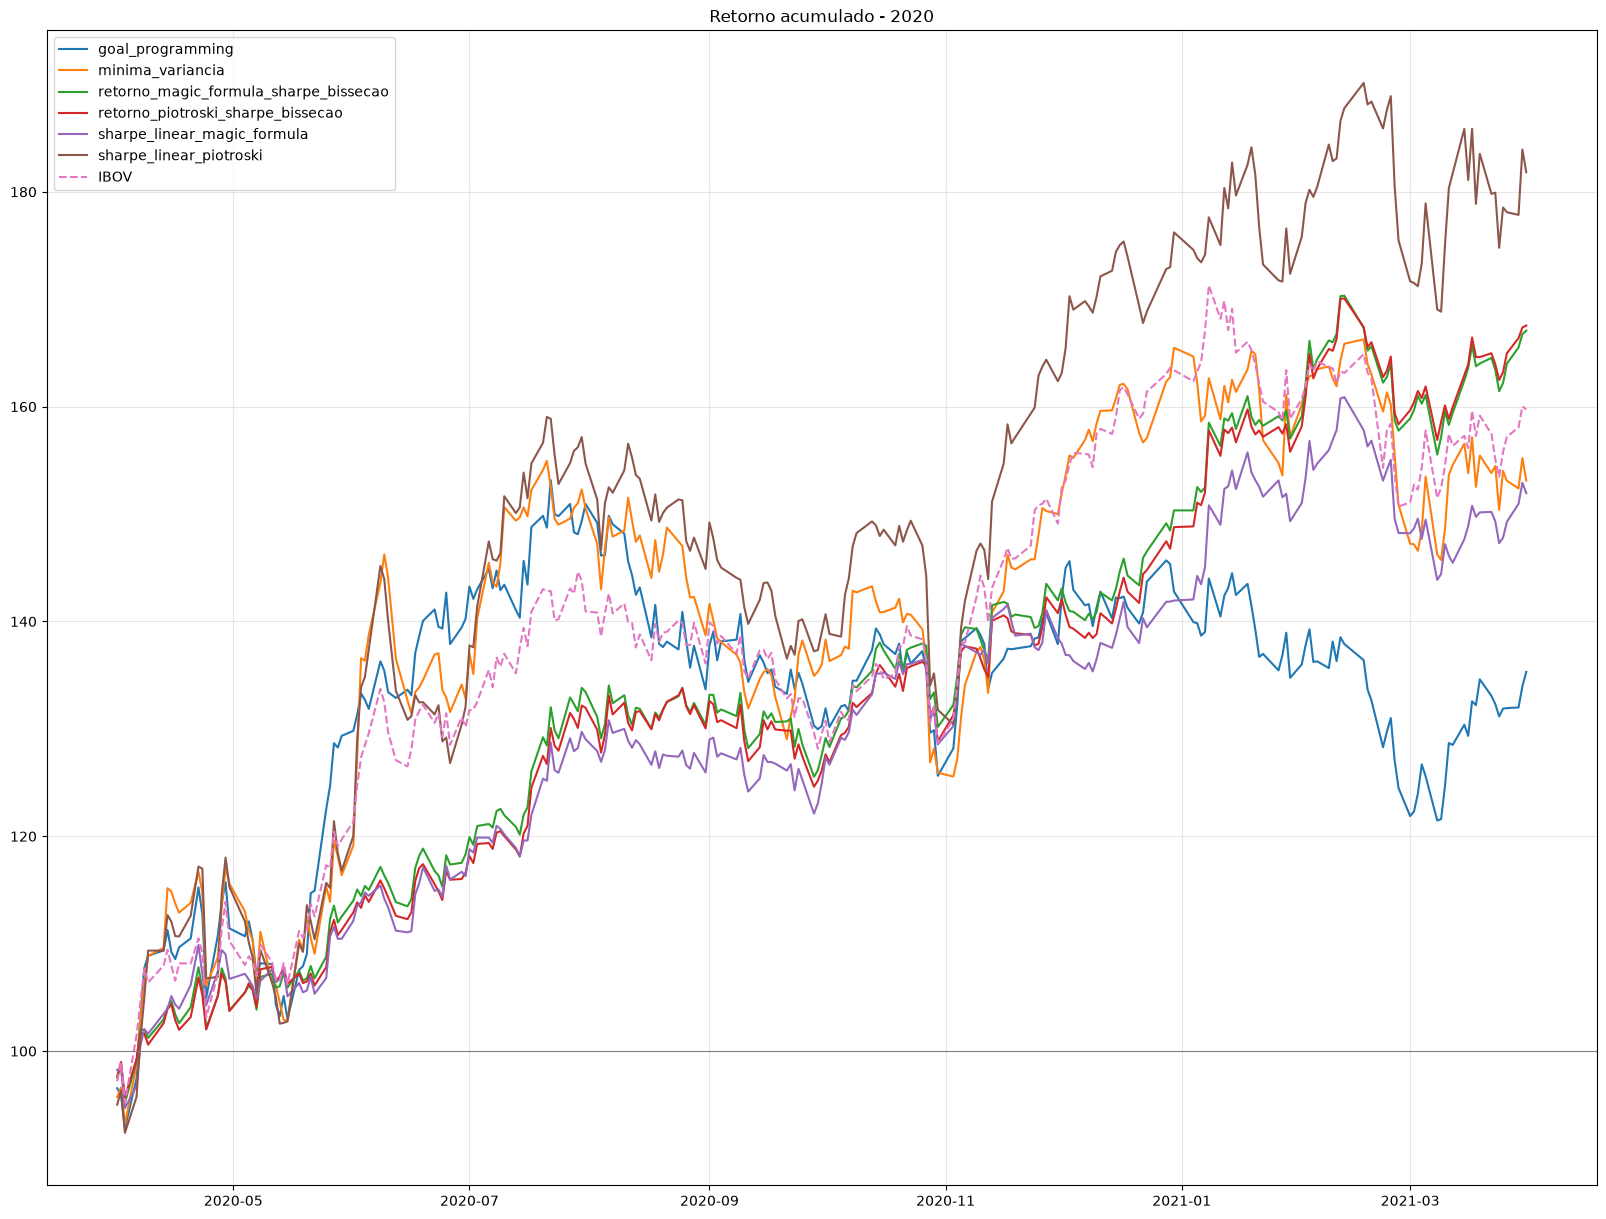

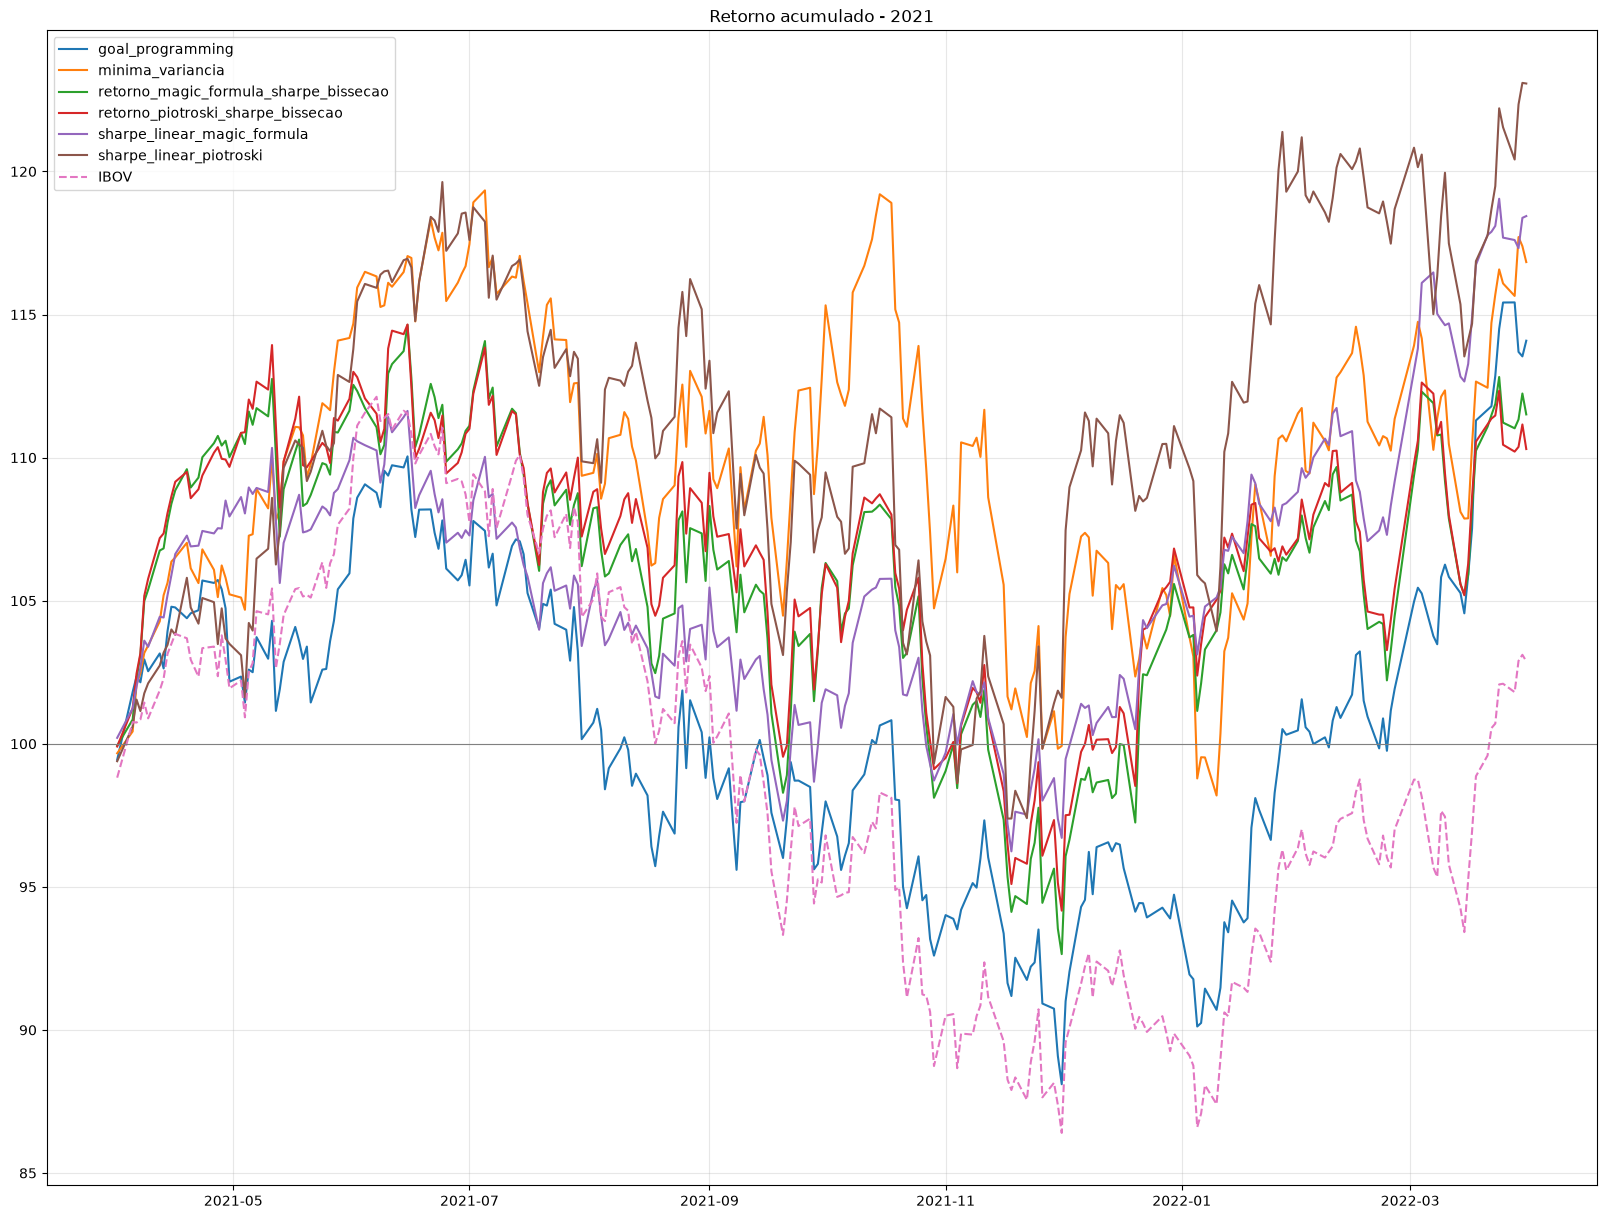

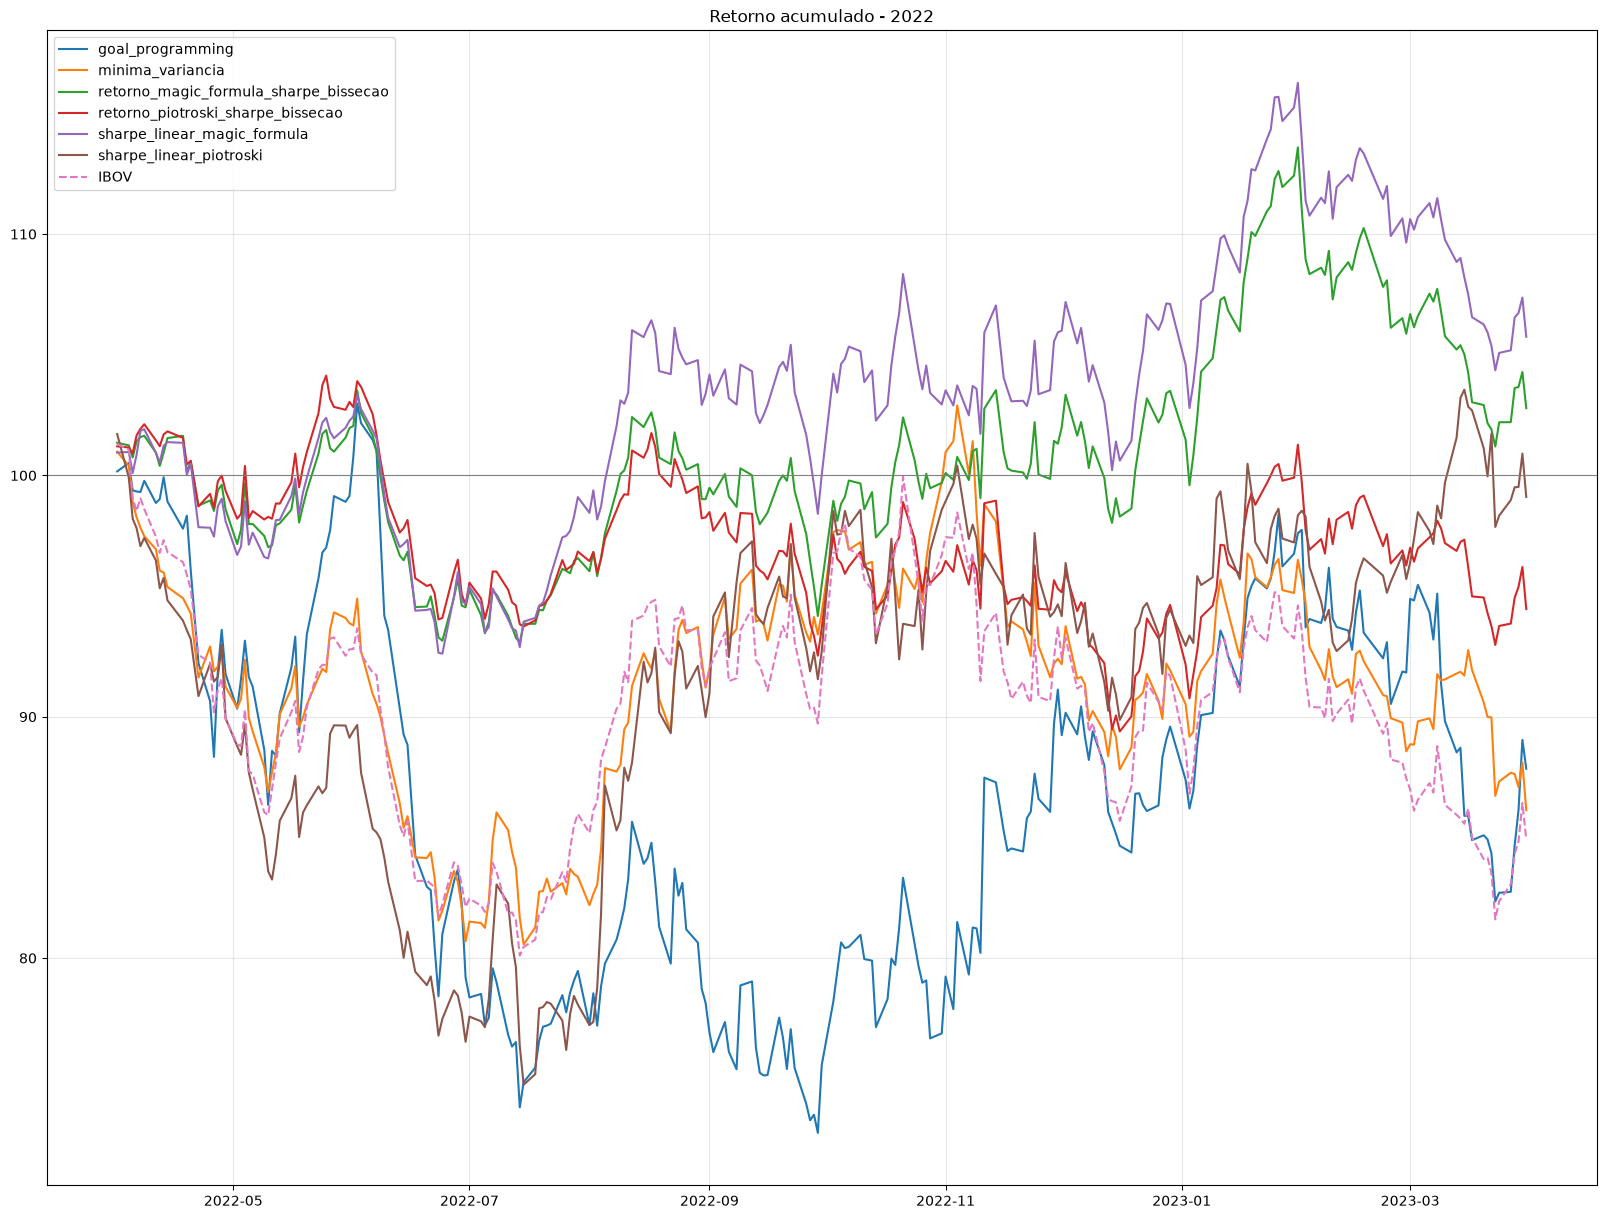

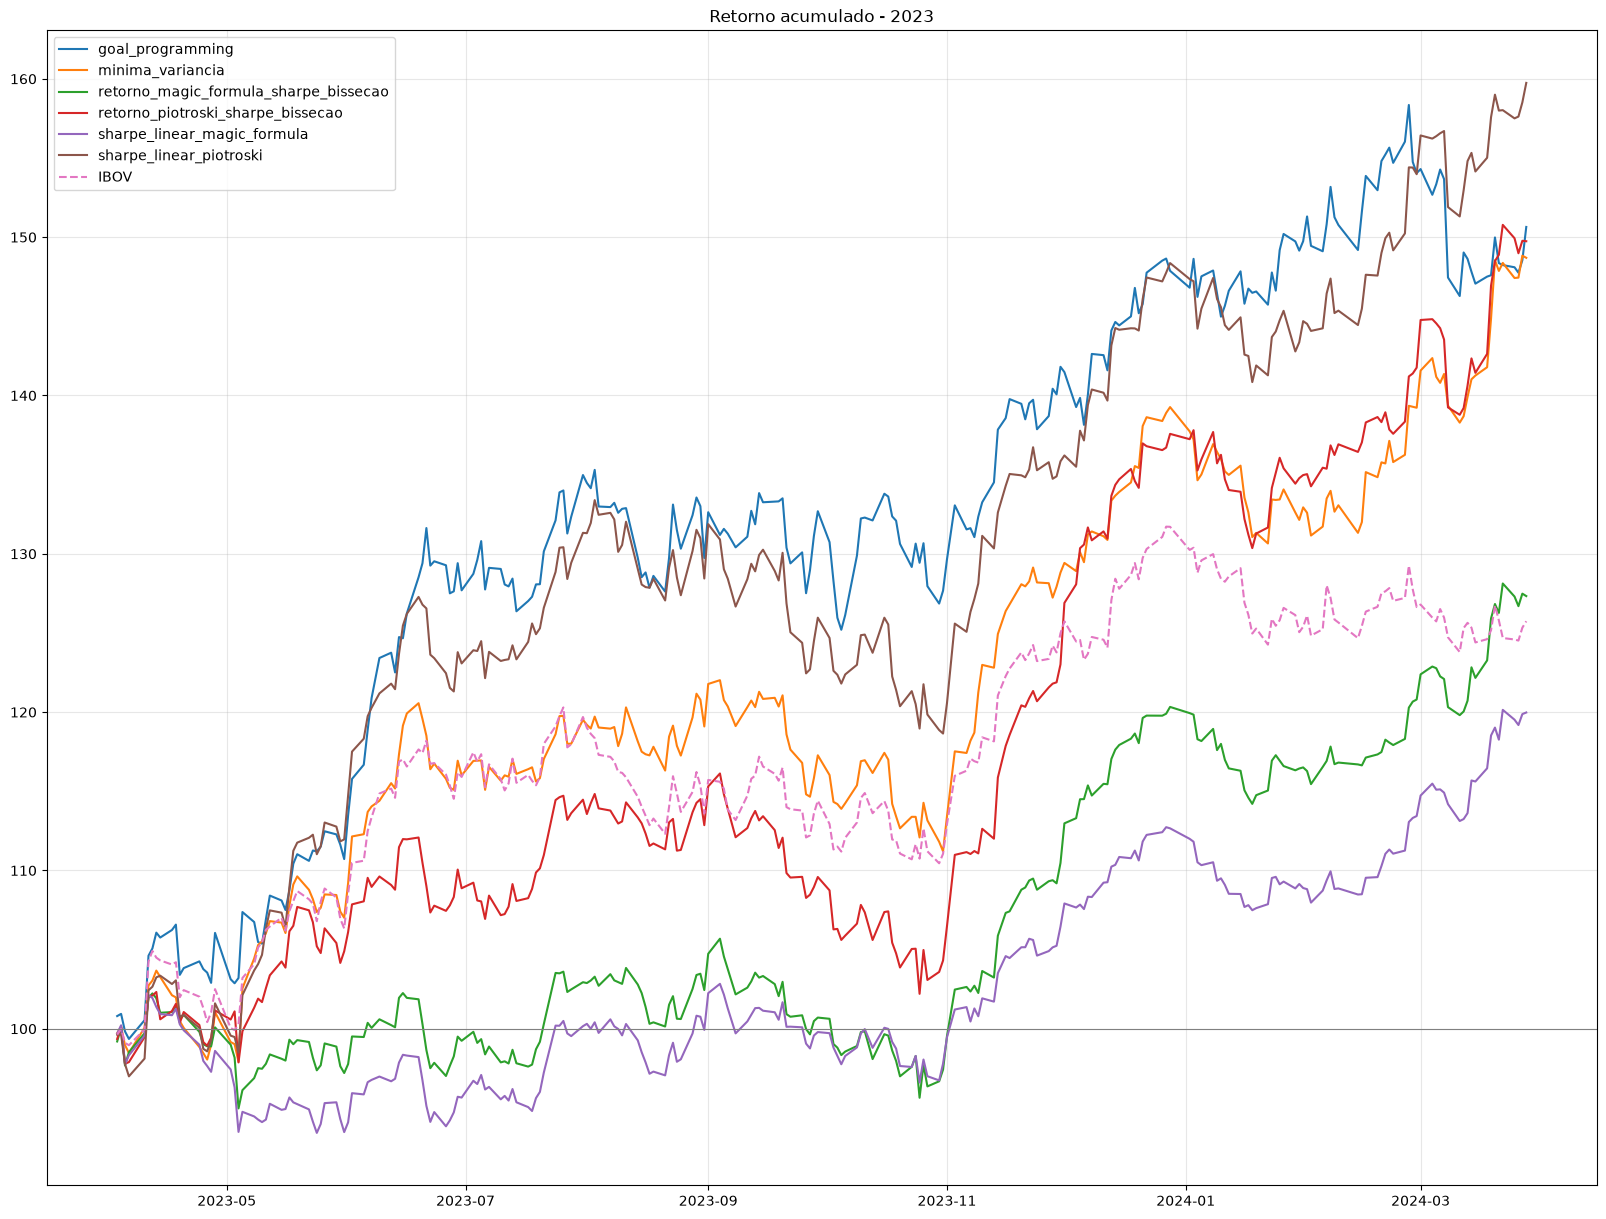

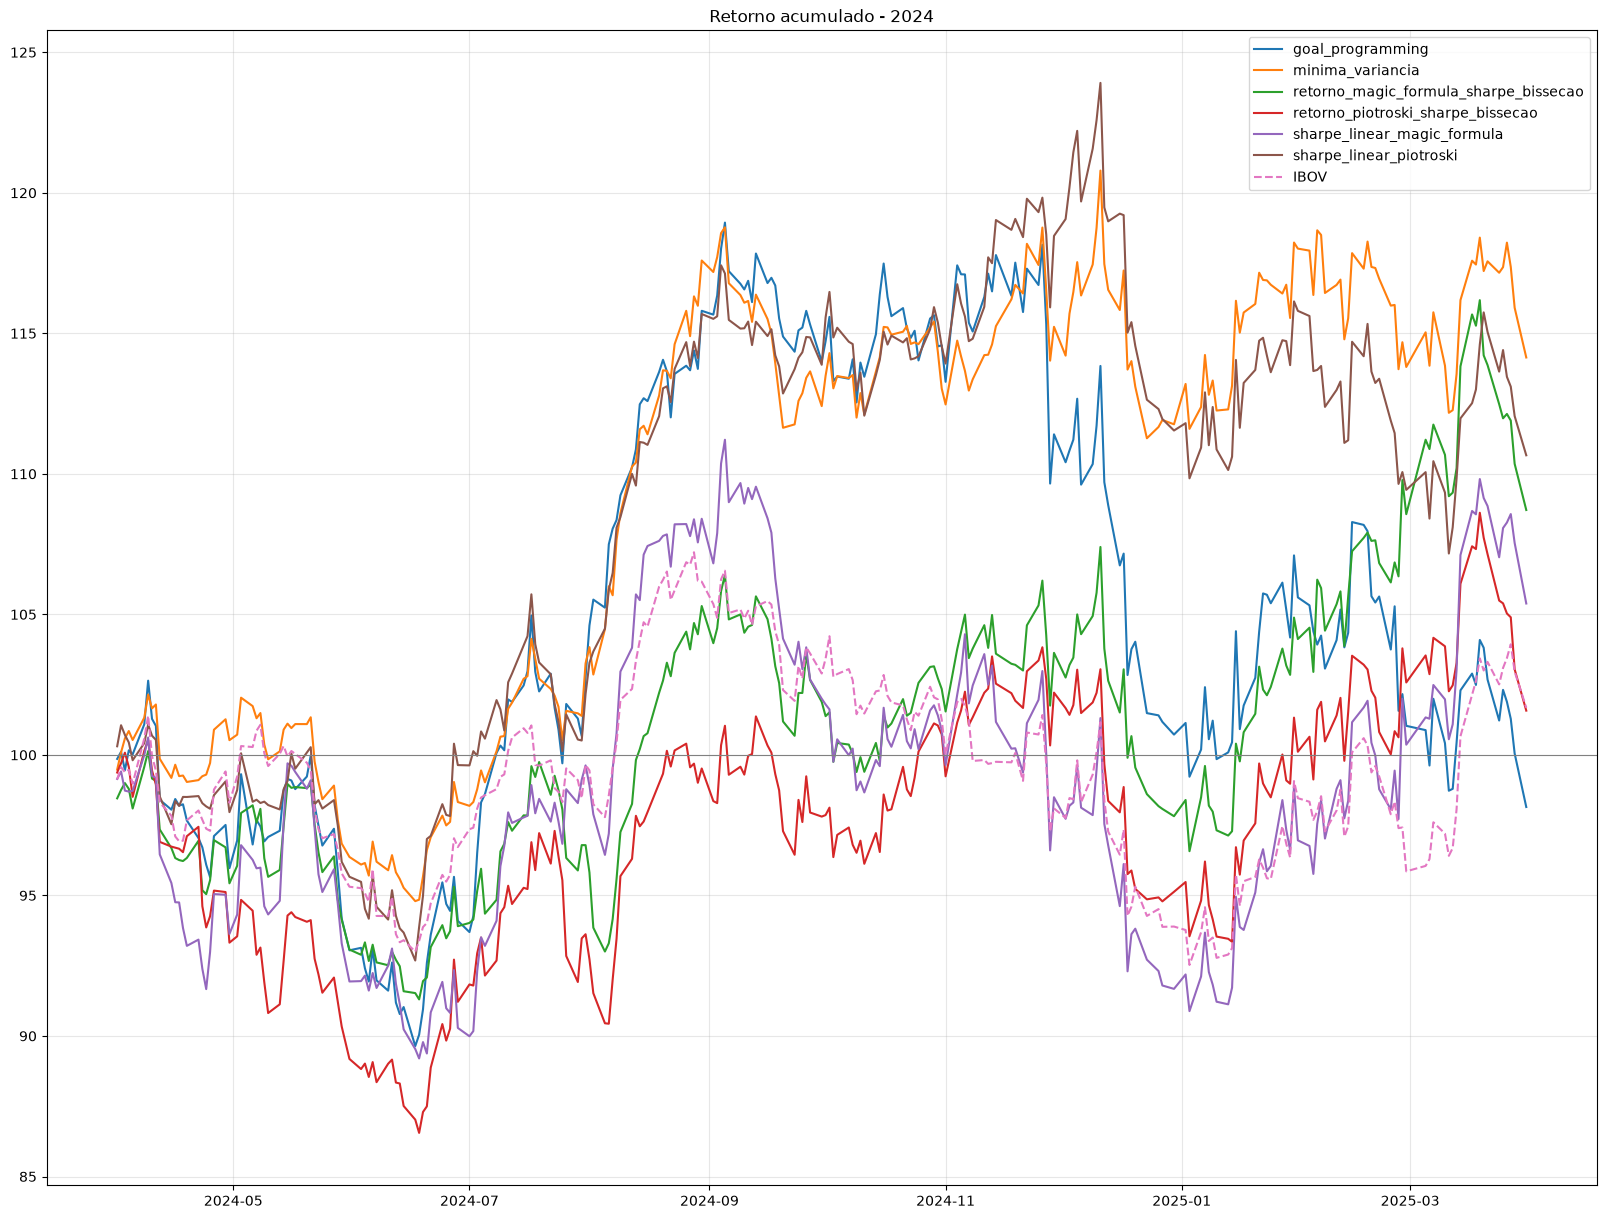

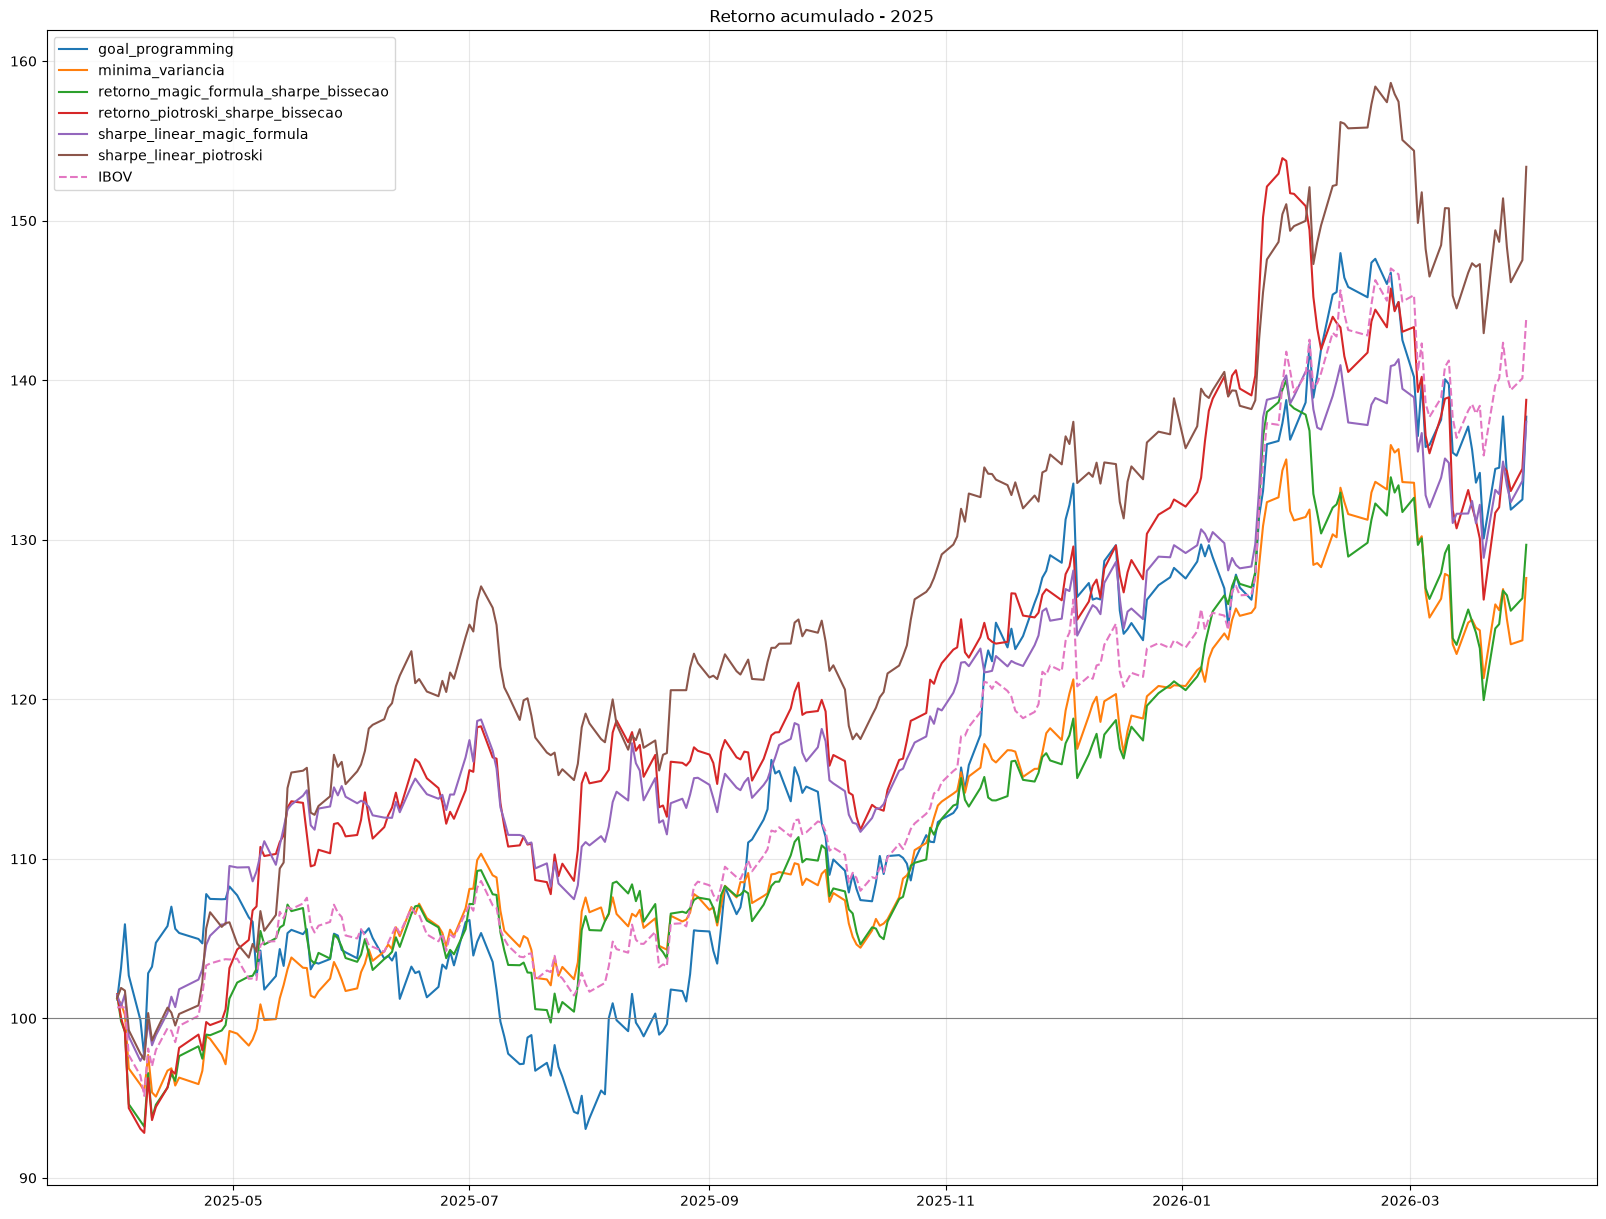

In [119]:
for ano in anos:
    plt.figure(figsize=(20, 15))

    for modelo, serie in dicio_anos[ano].items():
        plt.plot(serie.index, serie.values, label=modelo)

    df_ibov = pd.read_csv(f'../dados_retornos/plotagem/dados/ibov/df_ibov_{ano}.csv', index_col='Date', parse_dates=True)
    df_ibov = df_ibov['IBOV']
    ibov_acumulado = (df_ibov+1).cumprod()*100
    plt.plot(df_ibov.index, ibov_acumulado, label='IBOV', linestyle='--')

    plt.axhline(100, color='gray', linewidth=0.8)
    plt.title(f'Retorno acumulado - {ano}')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.savefig(f'acumulado_{ano}.png', dpi=300)
    plt.show()